# Clio-Infra over MCP

The tools a model would call, in the order it would call them. Clio has no
tools of its own: it is served by the catalog and the stored-series tools, the
same as WONDER, NVSR and Voteview.

The order is not a convention, it is enforced. The stored-series tools take
**ids** and never list — Clio alone is 11,042 series — so every lookup starts at
the catalog, which is capped and says how much it left out.

    series_catalog_concepts  →  series_catalog_search  →  timeseries_source_list  →  timeseries_source_data
         what exists             which series, by facet      coverage, by id            observations, by id

The MCP server must be running.

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
sys.path.append("../")
sys.path.append("../../")

from matplotlib import pyplot

from lib import config
from utils import (call_tool, concepts, describe, get_series, ids, list_mcp_tools,
                   plot_group, search_catalog, show_tool_schema)

pyplot.style.use(config.glyfish_style)

## The tools involved

In [2]:
await list_mcp_tools(("series_catalog", "timeseries_source"))

timeseries_source_list: Describe stored time series by id — identity, coverage and staleness, without observations. Takes 1 to 200 native_ids; it does not enumerate. To find series, use series_catalog_search (filter by 'timeseries_source', concept or facets) and take the ids from each entry's 'retrieval' block. Returns {'series': [...], 'total', 'returned', 'missing'} — 'missing' lists ids not stored. For the observations themselves, use timeseries_source_data.
timeseries_source_data: Return one stored time series in full, with its observations, from meida's database. 'source' and 'native_id' both come from timeseries_source_list — call that first rather than guessing an id. Pass 'frequency' only if an id is ambiguous. Observation values are strings — cast as needed.
timeseries_source_stale: List stored series that are due for an update — past their refresh horizon. These sources have no live API (CDC WONDER is throttled behind a bot filter; NVSR is a manual annual download), so refres

## The listing tool cannot list

`timeseries_source_list` requires `native_ids` — between 1 and 200 of them — and
says so in the schema a model reads. A call without them is refused before it
reaches the database.

In [3]:
_ = await show_tool_schema("timeseries_source_list")

timeseries_source_list
  Describe stored time series by id — identity, coverage and staleness, without observations. Takes 1 to 200 native_ids; it does not enumerate. To find series, use series_catalog_search (filter by 'timeseries_source', concept or facets) and take the ids from each entry's 'retrieval' block. Returns {'series': [...], 'total', 'returned', 'missing'} — 'missing' lists ids not stored. For the observations themselves, use timeseries_source_data.

  native_ids           array      required  1 to 200 native_ids, from series_catalog_search's 'retrieval
  source               any        optional  Only when an id is ambiguous across sources.


In [4]:
refused = await call_tool("timeseries_source_list", {"source": "clio"})
print("isError:", refused.isError)
print(refused.content[0].text.splitlines()[0][:120])

isError: True
Error executing tool timeseries_source_list: 1 validation error for timeseries_source_listArguments


## What exists

Each Clio indicator is a concept, one series per country.

In [5]:
available = await concepts()
print(f"{len(available)} indicators, {sum(c['series_count'] for c in available):,} series")

86 indicators, 11,042 series


## Which series, by facet

Facets are `indicator`, `country`, `category`, `ccode` and `kind`. `kind` says
what a row is: **measured**, a **panel** filled for every country, or a model
**reconstruction** — and it is per indicator, so early values of a "measured"
indicator can still be estimates.

In [6]:
for kind in ("measured", "panel", "reconstruction"):
    found = await search_catalog(limit=1, kind=kind)
    print(f"  {kind:15s} {found['total']:6,d} series")

found = await search_catalog(concept="height", limit=200, kind="measured")
print(f"\nheight: {found['total']} countries, returned {found['returned']}")
earliest = sorted(found["entries"], key=lambda e: e["observation_start"])[:6]
for e in earliest:
    print(f"  {e['observation_start'][:4]}  {e['facets']['country']:18s} {e['units']}")

  measured         6,275 series


  panel            2,523 series


  reconstruction   2,244 series



height: 153 countries, returned 153
  1550  germany            cm
  1550  poland             cm
  1660  france             cm
  1700  russia             cm
  1710  ireland            cm
  1710  united_kingdom     cm


## Coverage, then the data

The catalog gives ids; `timeseries_source_list` describes them, naming any it
does not hold; `timeseries_source_data` returns one in full.

In [7]:
wanted = [e["retrieval"]["native_id"] for e in earliest[:4]] + ["clio/height/atlantis"]
coverage = await describe(wanted)
for s in coverage["series"]:
    print(f"  {s['native_id']:34s} {s['observation_count']:3d} obs  "
          f"{s['observation_start'][:4]}-{s['observation_end'][:4]}  {s['frequency']}")
print(f"  returned {coverage['returned']} of {coverage['total']}, missing {coverage['missing']}")

  clio/height/germany                 30 obs  1550-1980  Decadal
  clio/height/poland                  14 obs  1550-1980  Decadal
  clio/height/france                  27 obs  1660-1980  Decadal
  clio/height/russia                  31 obs  1700-2000  Decadal
  returned 4 of 5, missing ['clio/height/atlantis']


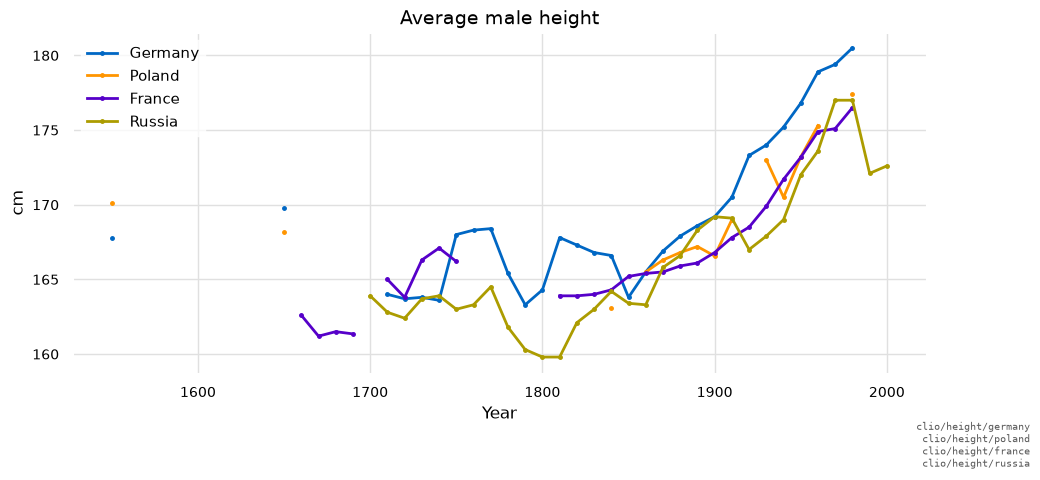

In [8]:
heights = [await get_series(i) for i in wanted[:4]]
plot_group(heights, [h["metadata"]["clio"]["country"][0] for h in heights],
           title="Average male height", ylabel=heights[0]["units"])

Height is decadal, so each point is a decade's average and the lines break
where a country has a decade missing. The dots are observations with a gap on
both sides.

## Filtering out what was not measured

Armed Conflicts has a row for all but a handful of country-years since 1500 — 0 or 1.
A search that should only see observed data excludes it by `kind`.

In [9]:
everything = await search_catalog(limit=1, country="united_kingdom")
measured = await search_catalog(limit=1, country="united_kingdom", kind="measured")
print(f"United Kingdom: {everything['total']} indicators, {measured['total']} of them measured")

conflict = await get_series("clio/armed_conflicts_internal/united_kingdom")
# values are strings as the workbook wrote them -- "1.0", not "1" -- so compare numbers
values = [float(o["value"]) for o in conflict["observations"]]
print(f"\n{conflict['title']}: {len(values)} years, "
      f"{values.count(1.0)} coded 1, {values.count(0.0)} coded 0 — kind "
      f"{conflict['metadata']['clio']['kind'][0]}")

United Kingdom: 85 indicators, 48 of them measured

Armed Conflicts (Internal) — United Kingdom: 501 years, 68 coded 1, 433 coded 0 — kind panel


For the same data through the Python clients, with no server in between, see
[`client.ipynb`](client.ipynb).